En este fichero realizaremos un modelo de clasificación de casas basado en los datos de diferentes portales inmobiliarios.

In [1]:
%load_ext rpy2.ipython

Error importing in API mode: ImportError('On Windows, cffi mode "ANY" is only "ABI".')
Trying to import in ABI mode.
c:\Users\super\PycharmProjects\analisis_datos_clasificacion\.venv\Lib\site-packages\rpy2\ipython\rmagic.py:96: UserWarning: The Python package `pandas` is strongly recommended when using `rpy2.ipython`. Unfortunately it could not be loaded, as we did not manage to load `numpy` in the first place (error: No module named 'numpy').
  warnings.warn('The Python package `pandas` is strongly '


In [2]:
%%R
lib_loc <- "lib_loc_100"

In [3]:
%%R
os <- Sys.info()[["sysname"]]

Cargamos librerias

In [4]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))

if (!require("psych", lib.loc = lib_loc)) install.packages("psych", lib = lib_loc)
library(psych, lib.loc = lib_loc)
if (!require("plyr", lib.loc = lib_loc)) install.packages("plyr", lib = lib_loc)
library(plyr, lib.loc = lib_loc)
if (!require("Rmisc", lib.loc = lib_loc)) install.packages("Rmisc", lib = lib_loc)
library(Rmisc, lib.loc = lib_loc)
if (!require("dplyr", lib.loc = lib_loc)) install.packages("dplyr", lib = lib_loc)
library(dplyr, lib.loc = lib_loc)
if (!require("GGally", lib.loc = lib_loc)) install.packages("GGally", lib = lib_loc)
library(GGally, lib.loc = lib_loc)
if (!require("corrplot", lib.loc = lib_loc)) install.packages("corrplot", lib = lib_loc)
library(corrplot, lib.loc = lib_loc)
if (!require("survey", lib.loc = lib_loc)) install.packages("survey", lib = lib_loc)
library(survey, lib.loc = lib_loc)
if (!require("mitools", lib.loc = lib_loc)) install.packages("mitools", lib = lib_loc)
library(mitools, lib.loc = lib_loc)
if (!require("relaimpo", lib.loc = lib_loc)) install.packages("relaimpo", lib = lib_loc)
library(relaimpo, lib.loc = lib_loc)
if (!require("FSelectorRcpp", lib.loc = lib_loc)) install.packages("FSelectorRcpp", lib = lib_loc)
library(FSelectorRcpp, lib.loc = lib_loc)
if (!require("ranger", lib.loc = lib_loc)) install.packages("ranger", lib = lib_loc)
library(ranger, lib.loc = lib_loc)
if (!require("Boruta", lib.loc = lib_loc)) install.packages("Boruta", lib = lib_loc)
library(Boruta, lib.loc = lib_loc)
if (!require("randomForest", lib.loc = lib_loc)) install.packages("randomForest", lib = lib_loc)
library(randomForest, lib.loc = lib_loc)
if (!require("caret", lib.loc = lib_loc)) install.packages("caret", lib = lib_loc)
library(caret, lib.loc = lib_loc)
if (!require("e1071", lib.loc = lib_loc)) install.packages("e1071", lib = lib_loc)
library(e1071, lib.loc = lib_loc)

if (!require("ggsci", lib.loc = lib_loc)) install.packages("ggsci", lib = lib_loc)
library(ggsci, lib.loc = lib_loc)
if (!require("dendextend", lib.loc = lib_loc)) install.packages("dendextend", lib = lib_loc)
library(dendextend, lib.loc = lib_loc)
if (!require("factoextra", lib.loc = lib_loc)) install.packages("factoextra", lib = lib_loc)
library(factoextra, lib.loc = lib_loc)
if (!require("FactoMineR", lib.loc = lib_loc)) install.packages("FactoMineR", lib = lib_loc)
library(FactoMineR, lib.loc = lib_loc)
if (!require("nFactors", lib.loc = lib_loc)) install.packages("nFactors", lib = lib_loc)
library(nFactors, lib.loc = lib_loc)


if(os=="Darwin"){
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps_3.2.tgz", lib = lib_loc, repos = NULL, type = "mac.binary")
    library(leaps, lib.loc = lib_loc)
}else{
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps", lib = lib_loc)
    library(leaps, lib.loc = lib_loc)
}

Cargando paquete requerido: psych
Cargando paquete requerido: plyr
Cargando paquete requerido: Rmisc
Cargando paquete requerido: lattice
Cargando paquete requerido: dplyr

Adjuntando el paquete: 'dplyr'

The following objects are masked from 'package:plyr':

    arrange, count, desc, failwith, id, mutate, rename, summarise,
    summarize

The following objects are masked from 'package:stats':

    filter, lag

The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union

Cargando paquete requerido: GGally
Cargando paquete requerido: ggplot2

Adjuntando el paquete: 'ggplot2'

The following objects are masked from 'package:psych':

    %+%, alpha

Cargando paquete requerido: corrplot
corrplot 0.95 loaded
Cargando paquete requerido: survey
Cargando paquete requerido: grid
Cargando paquete requerido: Matrix
Cargando paquete requerido: survival

Adjuntando el paquete: 'survey'

The following object is masked from 'package:graphics':

    dotchart

Cargando 

# Carga del fichero

In [5]:
%%R

dfMedidas <- read.csv("apartment+for+rent+classified/apartments_for_rent_classified_100K.csv", 
                      sep = ";", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      na.strings = c("null", "NULL", "", " ", "NA", "None"),
                      header = TRUE, 
                      fill = TRUE)


# Visualizamos los datos

In [6]:
%%R
head(dfMedidas, 5)

          id               category                           title
1 5668640009 housing/rent/apartment      One BR 507 & 509 Esplanade
2 5668639818 housing/rent/apartment     Three BR 146 Lochview Drive
3 5668639686 housing/rent/apartment Three BR 3101 Morningside Drive
4 5668639659 housing/rent/apartment           Two BR 209 Aegean Way
5 5668639374 housing/rent/apartment        One BR 4805 Marquette NE
                                                                                                                                                          body
1            This unit is located at 507 & 509 Esplanade, Redondo Beach, 90277, CAMonthly rental rates range from $2195We have 1 beds units available for rent
2              This unit is located at 146 Lochview Drive, Newport News, 23602, VAMonthly rental rates range from $1250We have 3 beds units available for rent
3               This unit is located at 3101 Morningside Drive, Raleigh, 27607, NCMonthly rental rates range from $

Analizamos los tipos de variables

In [7]:
%%R
str(dfMedidas)

'data.frame':	52746 obs. of  22 variables:
 $ id           : num  5.67e+09 5.67e+09 5.67e+09 5.67e+09 5.67e+09 ...
 $ category     : Factor w/ 6 levels "housing/rent",..: 2 2 2 2 2 2 2 2 2 2 ...
 $ title        : Factor w/ 35113 levels "$1,000 / One BR - Great Deal. MUST SEE!",..: 19260 28417 28678 30953 19191 31727 31471 30624 30770 30564 ...
 $ body         : Factor w/ 50995 levels "'s growing 4 Corners Area, Corners Apartments offers more of what Florida residents are craving! These exquisit"| __truncated__,..: 43340 40189 42082 41045 43200 44449 45210 39464 40152 39179 ...
 $ amenities    : Factor w/ 7397 levels " It is 1 of a kind- West side luxurious and amenities with East side rents. Residents can meet friends in the p"| __truncated__,..: NA NA NA NA NA NA NA NA NA NA ...
 $ bathrooms    : Factor w/ 21 levels "1","1.5","2",..: 1 2 3 1 1 2 3 3 1 3 ...
 $ bedrooms     : Factor w/ 11 levels "0","1","2","3",..: 2 4 4 3 2 3 3 3 3 3 ...
 $ currency     : Factor w/ 6 levels "1","2","3

# EDA

Como podemos ver todas las variables son categóricas, algo que no tiene sentido con variables como "price", "bathrooms" o "longitude", así que cambiamos los tipos de datos a los reales o que tienen sentido:

In [8]:
%%R
categoricas <- c(
  "category", "title", "body", "amenities", "currency",
  "has_photo", "pets_allowed", "price_display",
  "price_type", "cityname", "state", "source"
)

numericas <- c(
  "id", "bathrooms", "bedrooms", "price",
  "latitude", "longitude", "square_feet"
)

ordinales <- c("time")


dfMedidas[categoricas] <- lapply(dfMedidas[categoricas], as.factor)

dfMedidas[numericas] <- lapply(dfMedidas[numericas], function(x) {
  as.numeric(as.character(x))
})

dfMedidas$time <- as.numeric(as.character(dfMedidas$time))
dfMedidas$latitude  <- as.numeric(as.character(dfMedidas$latitude))
dfMedidas$longitude <- as.numeric(as.character(dfMedidas$longitude))


In addition: Warning messages:
1: In FUN(X[[i]], ...) : NAs introduced by coercion
2: In FUN(X[[i]], ...) : NAs introduced by coercion
3: In FUN(X[[i]], ...) : NAs introduced by coercion
4: In FUN(X[[i]], ...) : NAs introduced by coercion
5: In FUN(X[[i]], ...) : NAs introduced by coercion
6: In FUN(X[[i]], ...) : NAs introduced by coercion
7: In (function (expr, envir = parent.frame(), enclos = if (is.list(envir) ||  :
  NAs introduced by coercion


In [9]:
%%R
str(dfMedidas)

'data.frame':	52746 obs. of  22 variables:
 $ id           : num  5.67e+09 5.67e+09 5.67e+09 5.67e+09 5.67e+09 ...
 $ category     : Factor w/ 6 levels "housing/rent",..: 2 2 2 2 2 2 2 2 2 2 ...
 $ title        : Factor w/ 35113 levels "$1,000 / One BR - Great Deal. MUST SEE!",..: 19260 28417 28678 30953 19191 31727 31471 30624 30770 30564 ...
 $ body         : Factor w/ 50995 levels "'s growing 4 Corners Area, Corners Apartments offers more of what Florida residents are craving! These exquisit"| __truncated__,..: 43340 40189 42082 41045 43200 44449 45210 39464 40152 39179 ...
 $ amenities    : Factor w/ 7397 levels " It is 1 of a kind- West side luxurious and amenities with East side rents. Residents can meet friends in the p"| __truncated__,..: NA NA NA NA NA NA NA NA NA NA ...
 $ bathrooms    : num  1 1.5 2 1 1 1.5 2 2 1 2 ...
 $ bedrooms     : num  1 3 3 2 1 2 2 2 2 2 ...
 $ currency     : Factor w/ 6 levels "1","2","3","5",..: 6 6 6 6 6 6 6 6 6 6 ...
 $ fee          : Factor w/ 4 

Como podemos observar hay un total de 52746 instancias con 22 variables.
Estas variables se pueden dividir en categóricas, numéricas y una ordinal:

1)   Categóricas:
* category (Variable Objetivo): Categoría de la casa
* title: Título de la oferta
* body: Cuerpo de la oferta
* amenities: Comodidades
* currency: Moneda en la que está el precio
* has_photo: Tiene foto del apartamento o no
* pets_allowed: Permite o no mascotas (None, o lista con las opciones)
* price_display: Precio pero con el símbolo de la moneda en la que está
* price_type: Tipo de pago (Mensual, ...)
* cityname: Ciudad
* state: Estado
* source: Plataforma donde está la oferta


2)   Numéricas:
* id: Identificador de la casa
* bathrooms: Número de baños
* bedrooms: Número de habitaciones
* price: Precio de la casa (Número)
* latitude: Coordenada de latitud
* longitude: Coordenada de longitud
* address: Dirección
* fee: Señal (Número o "No")
* square_feet: Metros cuadrados

3) Ordinales:
* time: Tiempo desde que se creó la oferta


Cabe destacar que muchos de los valores numéricos no son de tipo entero, por lo que habrá que tratar los datos antes de tratar con ellos.

Para conocer los datos con más detalle hay que evaluar los siguientes conceptos:


*   Columnas faltantes o irrelevantes
*   Variables categóricas con mayor cardinalidad
*   Variables con valores faltantes
*   Correlación de las variables numéricas

In [10]:
%%R
describe(dfMedidas)

               vars     n          mean           sd        median
id                1 52746 5386522712.06 196424638.35 5508770378.50
category*         2 52739          2.00         0.04          2.00
title*            3 52739      16996.45     10242.46      16399.00
body*             4 52738      25447.56     14862.48      25334.50
amenities*        5 43034       5244.46      2224.16       6130.00
bathrooms         6 52681          1.43         0.55          1.00
bedrooms          7 52666          1.73         0.77          2.00
currency*         8 52739          6.00         0.05          6.00
fee*              9 52739          1.01         0.17          1.00
has_photo*       10 52730          3.43         0.65          4.00
pets_allowed*    11 21516         14.95         0.36         15.00
price            12 52718       1523.55       898.94       1349.00
price_display*   13 52738       1282.40      1134.14        784.00
price_type*      14 52739         20.00         0.22         2

En este caso podemos ver que hay algunas columnas irrelevantes, ya sea por ser de id o que no aporten información como id; title; body; price_display; address, o amenities o por ser de valores constantes como fee y currency.

En cuanto a la cardinalidad máxima podemos ver que la variable con mayor rango es el nombre de la ciudad, alcanzndo los 1574 valores.

En cuanto a los valores faltantes, hay que tratar los datos para que se identifiquen los null como valores nulos

In [11]:
%%R 
data.frame(
  NAs = colSums(is.na(dfMedidas)),
  Perc = colSums(is.na(dfMedidas)) / nrow(dfMedidas) * 100
)

                NAs        Perc
id                0  0.00000000
category          7  0.01327115
title             7  0.01327115
body              8  0.01516703
amenities      9712 18.41277064
bathrooms        65  0.12323209
bedrooms         80  0.15167027
currency          7  0.01327115
fee               7  0.01327115
has_photo        16  0.03033405
pets_allowed  31230 59.20828120
price            28  0.05308459
price_display     8  0.01516703
price_type        7  0.01327115
square_feet      27  0.05118872
address       45480 86.22454783
cityname        182  0.34504986
state           175  0.33177871
latitude         27  0.05118872
longitude        33  0.06256399
source            7  0.01327115
time             27  0.05118872


In [12]:
%%R

dfMedidas <- dfMedidas[,!names(dfMedidas) %in% c("id", "title", "body", "price_display", "address", "amenities", "fee", "currency", "pets_allowed")]

In [13]:
%%R
describe(dfMedidas)

            vars     n          mean          sd        median      trimmed
category*      1 52739          2.00        0.04          2.00  2.00000e+00
bathrooms      2 52681          1.43        0.55          1.00  1.38000e+00
bedrooms       3 52666          1.73        0.77          2.00  1.64000e+00
has_photo*     4 52730          3.43        0.65          4.00  3.53000e+00
price          5 52718       1523.55      898.94       1349.00  1.40469e+03
price_type*    6 52739         20.00        0.22         20.00  2.00000e+01
square_feet    7 52719        953.10      387.11        897.00  9.13550e+02
cityname*      8 52564       1175.15      731.86       1159.50  1.15835e+03
state*         9 52571         40.71       17.09         43.00  4.06500e+01
latitude      10 52719         36.99        5.05         37.38  3.70700e+01
longitude     11 52713        -91.79       15.90        -85.69 -9.06000e+01
source*       12 52739         35.15        1.30         35.00  3.50800e+01
time        

In [14]:
%%R
str(dfMedidas)

'data.frame':	52746 obs. of  13 variables:
 $ category   : Factor w/ 6 levels "housing/rent",..: 2 2 2 2 2 2 2 2 2 2 ...
 $ bathrooms  : num  1 1.5 2 1 1 1.5 2 2 1 2 ...
 $ bedrooms   : num  1 3 3 2 1 2 2 2 2 2 ...
 $ has_photo  : Factor w/ 4 levels "Cats,Dogs","No",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ price      : num  2195 1250 1395 1600 975 ...
 $ price_type : Factor w/ 21 levels "$1,650","$1,800",..: 20 20 20 20 20 20 20 20 20 20 ...
 $ square_feet: num  542 1500 1650 820 624 ...
 $ cityname   : Factor w/ 2601 levels "Abbeville","Aberdeen",..: 1926 1603 1902 2362 19 19 951 1204 397 403 ...
 $ state      : Factor w/ 69 levels "32.8004","33.7435",..: 18 64 43 18 48 48 64 19 68 18 ...
 $ latitude   : num  33.9 37.1 35.8 38.4 35.1 ...
 $ longitude  : num  -118.4 -76.5 -78.6 -122 -106.6 ...
 $ source     : Factor w/ 42 levels "-104.8622","-70.7371",..: 37 37 37 37 37 37 37 37 37 37 ...
 $ time       : num  1.58e+09 1.58e+09 1.58e+09 1.58e+09 1.58e+09 ...


Analizamos cada variable con histogramas:

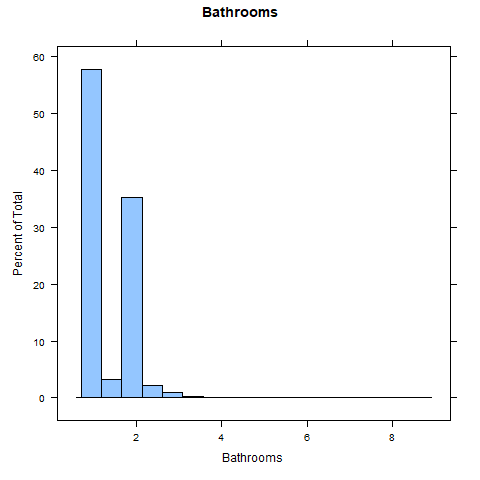

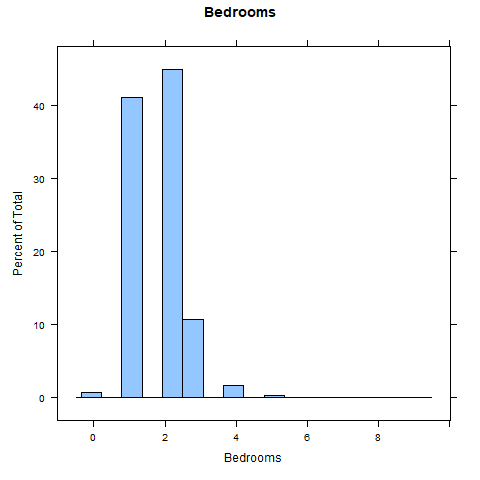

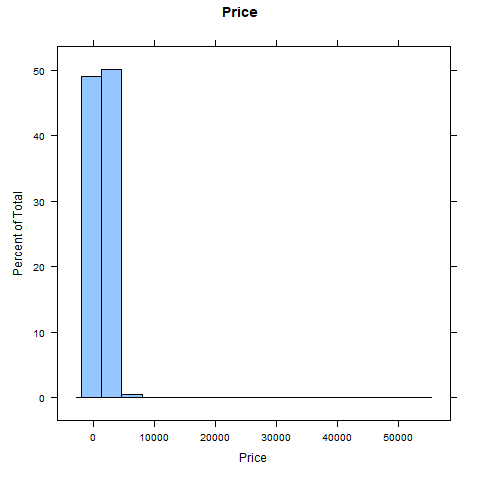

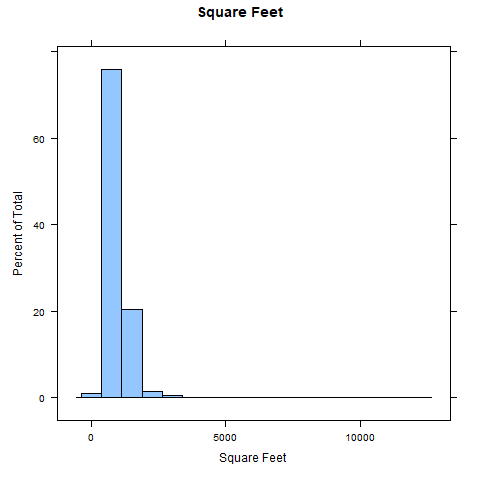

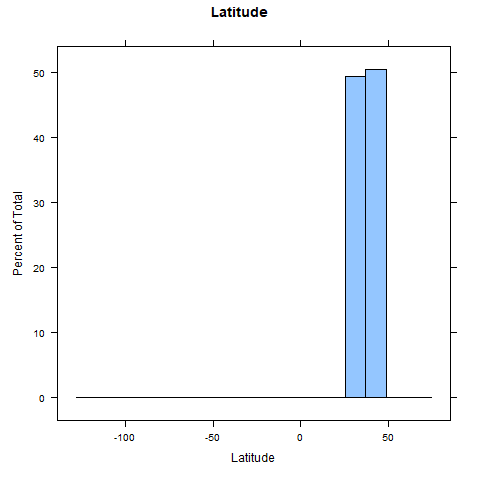

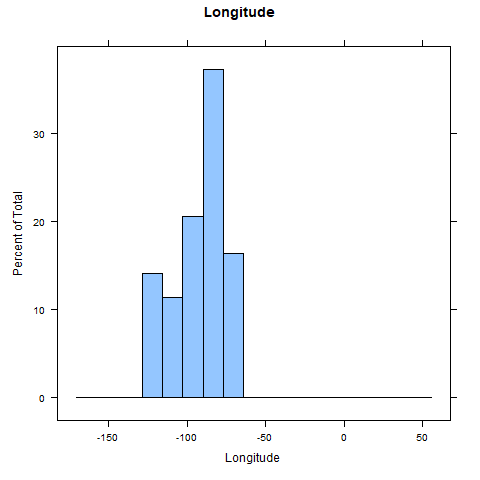

In [15]:
%%R

print(histogram(dfMedidas$bathrooms, main = "Bathrooms", xlab = "Bathrooms"))
print(histogram(dfMedidas$bedrooms, main = "Bedrooms", xlab = "Bedrooms"))
print(histogram(dfMedidas$price, main = "Price", xlab = "Price"))
print(histogram(dfMedidas$square_feet, main = "Square Feet", xlab = "Square Feet"))
print(histogram(dfMedidas$latitude, main = "Latitude", xlab = "Latitude"))
print(histogram(dfMedidas$longitude, main = "Longitude", xlab = "Longitude"))

Podemos ver valores raros en el rango de latitud, por lo que hacemos una comporbación

In [16]:
%%R
print(summary(dfMedidas$latitude))
print(summary(dfMedidas$longitude))

print(range(dfMedidas$latitude, na.rm = TRUE))
print(range(dfMedidas$longitude, na.rm = TRUE))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
-118.28   33.75   37.38   36.99   40.05   64.83      27 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
-159.37 -104.77  -85.69  -91.79  -78.19   44.49      33 
[1] -118.2794   64.8332
[1] -159.3698   44.4872


Efectivamente, hay valores que no cumplen el rango real de latitud, por lo que hacemos los cambios oportunos.

In [17]:
%%R
dfMedidas$latitude[
  dfMedidas$latitude < -90 | dfMedidas$latitude > 90
] <- NA

dfMedidas$longitude[
  dfMedidas$longitude < -180 | dfMedidas$longitude > 180
] <- NA

In [18]:
%%R
print(summary(dfMedidas$latitude))
print(summary(dfMedidas$longitude))

print(range(dfMedidas$latitude, na.rm = TRUE))
print(range(dfMedidas$longitude, na.rm = TRUE))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
 -85.52   33.75   37.38   37.00   40.05   64.83      29 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
-159.37 -104.77  -85.69  -91.79  -78.19   44.49      33 
[1] -85.5213  64.8332
[1] -159.3698   44.4872


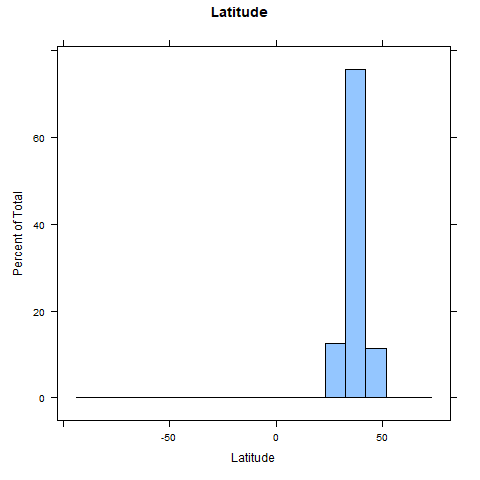

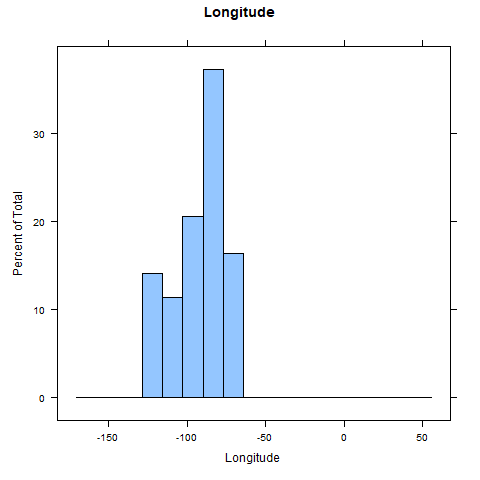

In [19]:
%%R
print(histogram(dfMedidas$latitude, main = "Latitude", xlab = "Latitude"))
print(histogram(dfMedidas$longitude, main = "Longitude", xlab = "Longitude"))

Podemos ver que todas las variables siguen una distribución normal, y podemos destacar la siguiente información:

* Podemos ver que la mayoría de precios está por debajo de los 10000 y los metros cuadrados tambien.
* Podemos ver que los valores de Longitud se concentran entere 60 y 130 aproximadamente, lo que tiene sentido dado que los Estados Unidos de América están comprendidos entre esas longitudes.
* En cuanto al número de habitaciones y baños podemos ver que, en general, no son muchos.

Evaluamos también la presencia de outliers con los diagramas de caja

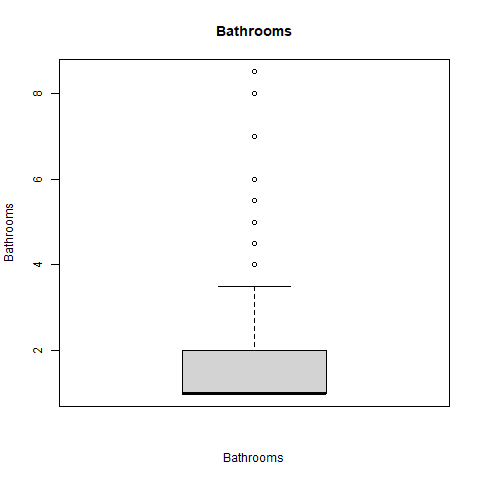

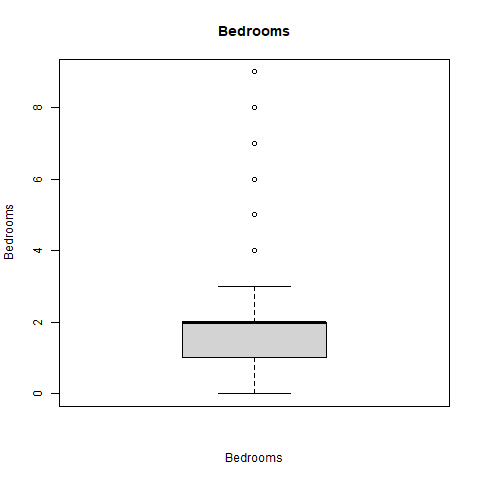

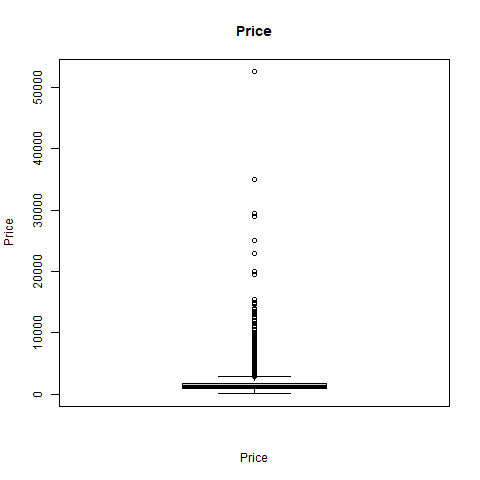

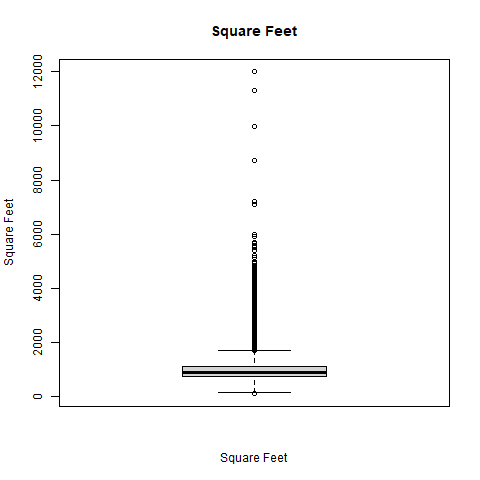

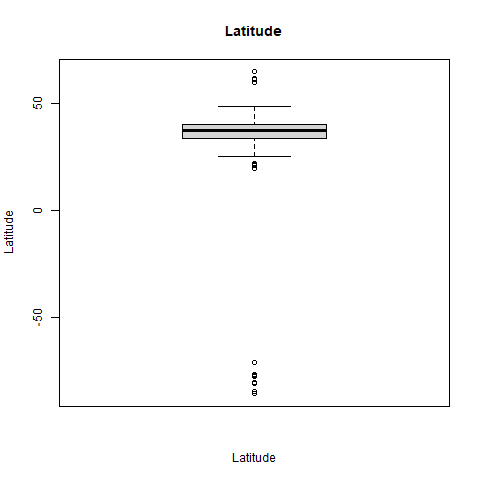

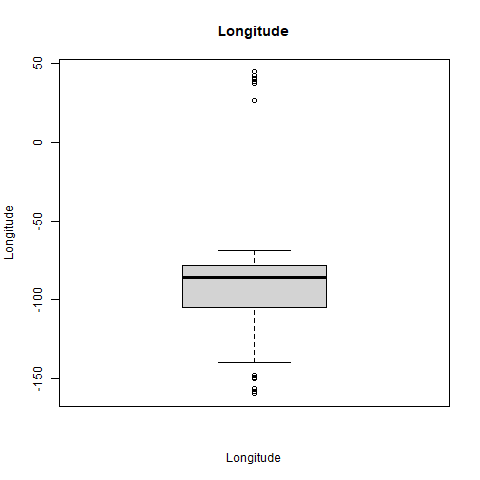

In [20]:
%%R
boxplot(dfMedidas$bathrooms, main = "Bathrooms", xlab = "Bathrooms", ylab = "Bathrooms")
boxplot(dfMedidas$bedrooms, main = "Bedrooms", xlab = "Bedrooms", ylab = "Bedrooms")
boxplot(dfMedidas$price, main = "Price", xlab = "Price", ylab = "Price")
boxplot(dfMedidas$square_feet, main = "Square Feet", xlab = "Square Feet", ylab = "Square Feet")
boxplot(dfMedidas$latitude, main = "Latitude", xlab = "Latitude", ylab = "Latitude")
boxplot(dfMedidas$longitude, main = "Longitude", xlab = "Longitude", ylab = "Longitude")

Podemos ver que todas las variables presentan Outliers, siendo el precio y los metros cuadrados aquellas variables con más, por ello, y para buscar alguna explicación, observamos el impacto de la localización geográfica en estas variables y la objetivo.

In addition: Warning messages:
1: Removed 40 rows containing missing values or values outside the scale range
(`geom_point()`). 
2: Removed 41 rows containing missing values or values outside the scale range
(`geom_point()`). 
3: Removed 41 rows containing missing values or values outside the scale range
(`geom_point()`). 


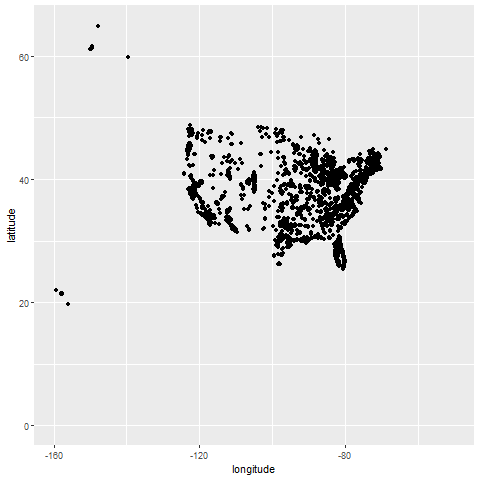

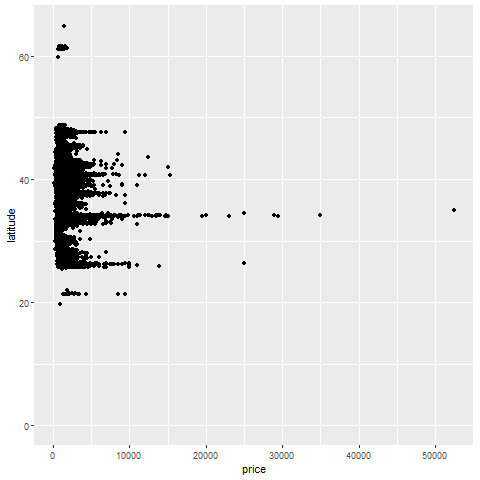

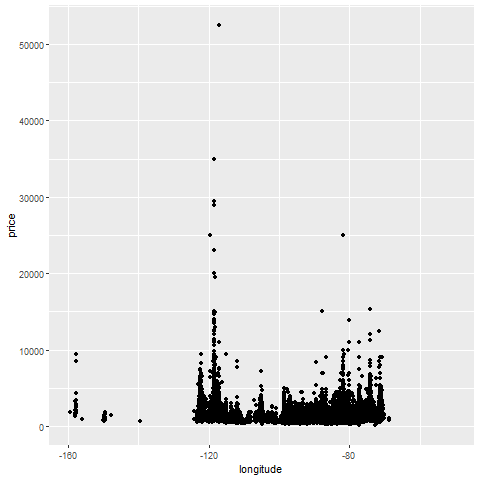

In [21]:
%%R
print(ggplot(dfMedidas, aes(x = longitude, y = latitude)) + geom_point() +
  scale_x_continuous(limits = c(-160, -50)) +
  scale_y_continuous(limits = c(0, 65)))

print(ggplot(dfMedidas, aes(x = price, y = latitude)) + geom_point() +
  scale_y_continuous(limits = c(0, 65)))
print(ggplot(dfMedidas, aes(x = longitude, y = price)) + geom_point() +
  scale_x_continuous(limits = c(-160, -50)))



R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: Removed 40 rows containing missing values or values outside the scale range
(`geom_point()`). 
  


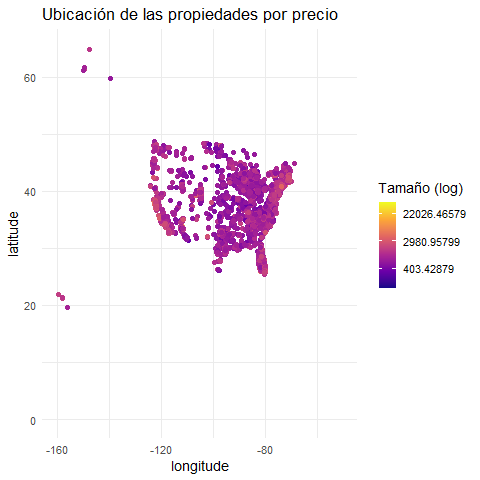

In [22]:
%%R

ggplot(dfMedidas, aes(x = longitude, y = latitude, color = price)) +
  geom_point() +
  scale_x_continuous(limits = c(-160, -50)) +
  scale_y_continuous(limits = c(0, 65)) +
  scale_color_viridis_c(option = "plasma", trans = "log") +
  labs(title = "Ubicación de las propiedades por precio",
       color = "Tamaño (log)") +
  theme_minimal(base_size = 14)

In addition: Warning messages:
1: Removed 40 rows containing missing values or values outside the scale range
(`geom_point()`). 
2: Removed 40 rows containing missing values or values outside the scale range
(`geom_point()`). 


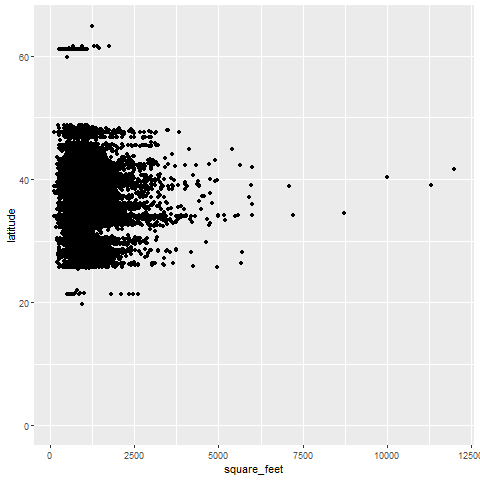

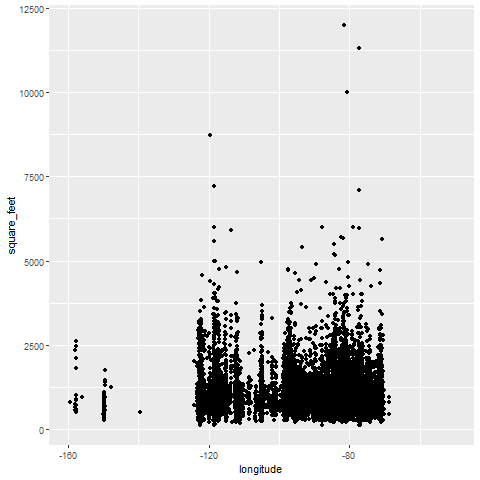

In [23]:
%%R
print(ggplot(dfMedidas, aes(x = square_feet, y = latitude)) + geom_point() +
scale_y_continuous(limits = c(0, 65)))
print(ggplot(dfMedidas, aes(x = longitude, y = square_feet)) + geom_point() +
scale_x_continuous(limits = c(-160, -50)))

Podemos ver que hay cierta relación entre la zona geográfica y las casas más grandes, además, se evalúa la relación con el tipo de casas (variable objeivo)

In addition: Warning message:
Removed 27 rows containing missing values or values outside the scale range
(`geom_point()`). 


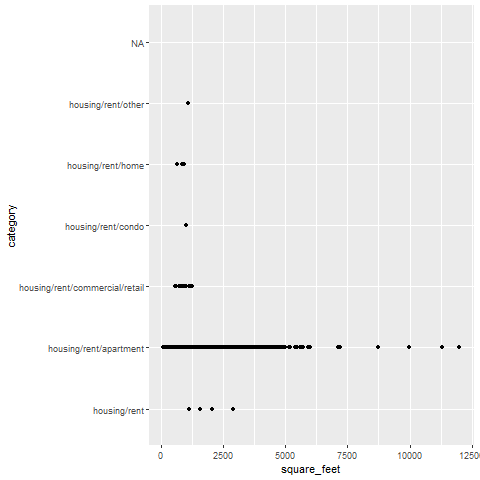

In [24]:
%%R
print(ggplot(dfMedidas, aes(x = square_feet, y = category)) + geom_point())

In [25]:
%%R
print(table(dfMedidas$category))
print(prop.table(table(dfMedidas$category))*100)


                  housing/rent         housing/rent/apartment 
                             4                          52688 
housing/rent/commercial/retail             housing/rent/condo 
                            42                              1 
             housing/rent/home             housing/rent/other 
                             3                              1 

                  housing/rent         housing/rent/apartment 
                    0.00758452                    99.90329737 
housing/rent/commercial/retail             housing/rent/condo 
                    0.07963746                     0.00189613 
             housing/rent/home             housing/rent/other 
                    0.00568839                     0.00189613 


De estas gráficas podemos sacar las siguientes conclusiones:

* En cuanto al precio de las viviendas, podemos observar que hay una zona geográfica que concentra los precios más altos (33/35º N, ~80º W y 120ºW).
* En cuanto al tamaño de las viviendas, podemos sacar dos conclusiones. 

    * Por un lado, las casas más grandes se agrupan en unas zonas geográficas concretas (~40º N, ~80º W y 120ºW).
    * Por otro lado, podemos ver que las casas más grandes son de la categoria apartamento, siendo esta la categoria con más número de casas.

Por todo esto, se puede ver que los valores que en un principio pueden parecer atípicos, muestran información acerca de una concentración geográfica de casas de mayor precio, así como un mayor tamaño de una categoría concreta de casas.

## Análisis de Correlación:

### Correlación entre las variables numéricas:

In [26]:
%%R

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
corr_test <- corr.test(num_vars)

# Correlaciones
print(round(corr_test$r, 2))


            bathrooms bedrooms price square_feet latitude longitude  time
bathrooms        1.00     0.68  0.33        0.72    -0.09     -0.01 -0.04
bedrooms         0.68     1.00  0.25        0.70     0.02      0.04  0.01
price            0.33     0.25  1.00        0.42     0.06     -0.11  0.04
square_feet      0.72     0.70  0.42        1.00    -0.04      0.06 -0.01
latitude        -0.09     0.02  0.06       -0.04     1.00      0.05  0.19
longitude       -0.01     0.04 -0.11        0.06     0.05      1.00 -0.01
time            -0.04     0.01  0.04       -0.01     0.19     -0.01  1.00


Y de una forma más visual:

R callback write-console: In addition:   
R callback write-console: There were 49 warnings (use warnings() to see them)  
R callback write-console: 
  


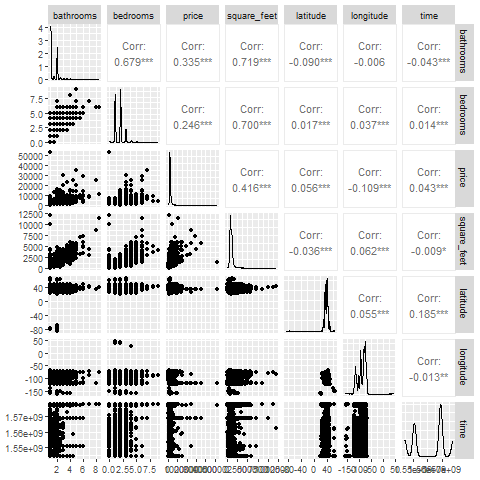

In [27]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
ggpairs(num_vars)

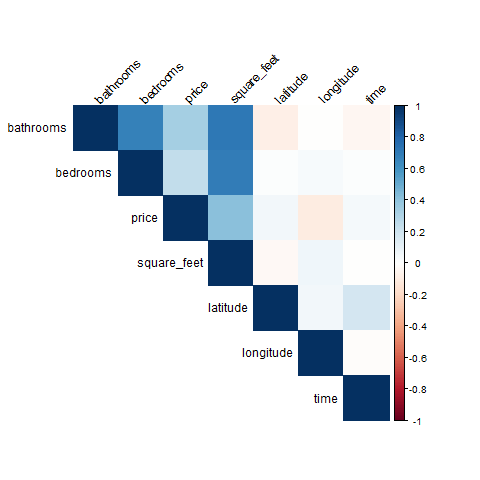

In [28]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
cor_matrix <- cor(num_vars, use = "complete.obs")

corrplot(corr_test$r,
        type = "upper", 
        method = "color", 
        tl.col = "black", 
        tl.srt = 45)

Podemos ver que las variables más relacionadas son el número de baños con los metros cuadrados (72%) y el número de dormitorios con el tamao de la vivienda (70%).  
Por otro lado, destaca la relación del número de dormitorios con el de baños (68%)

Estas relaciones tienen sentido, ya que, el tamaño de una vivienda viene dado por la suma del tamaño de sus habitaciones (dormitorios y baños), y el número de baños está directamente relacionado con el de dormitorios, pues normalmente hay casi tantos de uno como de otro.

Estas relaciones significativas habrá que tenerlas en cuenta en el futuro, ya que, la informaciñon que aportan cada una de las variables de cada par puede llegar a ser redundante.


### Correlación con la variable objetivo:

Evaluamos la correlación de las variables numéricas con la variable objetivo

In [29]:
%%R
library(ggplot2)

target <- "category"
dfMedidas[[target]] <- as.numeric(as.factor(dfMedidas[[target]])) - 1

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
correlations <- cor(num_vars, use = "complete.obs", method = "pearson")[, target]

cor_df <- data.frame(
  Variable = names(correlations),
  Correlation = correlations
)
cor_df <- cor_df[cor_df$Variable != target, ]
cor_df <- cor_df[order(-abs(cor_df$Correlation)), ]

print(cor_df)

               Variable  Correlation
time               time  0.017645674
longitude     longitude  0.016590056
latitude       latitude  0.009590018
square_feet square_feet -0.004012221
price             price  0.003963996
bathrooms     bathrooms -0.003735934
bedrooms       bedrooms -0.003308456


Podemos ver que los valores no son lo suficientemente significativos como para tomar una decisión.

## Selección de Atributos:

Se descarta el uso de algoritmos de selección por filtrado debido a que es un problema de clasificación con la variable objetivo no numérica ordinal, por ello analizaremos la importancia de los atributos mediante ranking y embedido, para, de esta forma, poder evaluar la posibilidad de eliminar algún atributo más. 

### Selección por Ranking

Utilizamos Boruta como métrica de importancia de atributos, sin embargo, antes evaluamos la presencia de valores faltantes en la variable objetivo:

In [30]:
%%R
sum(is.na(dfMedidas$category))


[1] 7


Podemos ver que hay 7 instancias en las que no hay valor para la variable objetivo, como son tan pocas respecto al conjunto total de datos y no aportan información, borramos esas filas.

In [31]:
%%R
dfMedidas <- dfMedidas[!is.na(dfMedidas$category), ]

In [ ]:
"""%%R
formula <- to_formula( c("latitude", "longitude", "price", "time", "square_feet",
                         "bathrooms", "bedrooms"), "category")


out.boruta <- Boruta(formula, data = dfMedidas)
plot(out.boruta, cex.axis = 0.8, las=1)
print(out.boruta)
attStats(out.boruta)"""

Growing trees.. Progress: 18%. Estimated remaining time: 2 minutes, 25 seconds.
Growing trees.. Progress: 35%. Estimated remaining time: 1 minute, 54 seconds.
Growing trees.. Progress: 52%. Estimated remaining time: 1 minute, 25 seconds.
Growing trees.. Progress: 69%. Estimated remaining time: 54 seconds.
Growing trees.. Progress: 88%. Estimated remaining time: 22 seconds.
Computing permutation importance.. Progress: 51%. Estimated remaining time: 30 seconds.
Computing permutation importance.. Progress: 100%. Estimated remaining time: 0 seconds.
Growing trees.. Progress: 15%. Estimated remaining time: 2 minutes, 50 seconds.
Growing trees.. Progress: 30%. Estimated remaining time: 2 minutes, 26 seconds.
Growing trees.. Progress: 46%. Estimated remaining time: 1 minute, 50 seconds.
Growing trees.. Progress: 63%. Estimated remaining time: 1 minute, 11 seconds.
Growing trees.. Progress: 81%. Estimated remaining time: 37 seconds.
Growing trees.. Progress: 97%. Estimated remaining time: 6 se

Exception ignored from cffi callback <function _callback_wrapper_ABI.<locals>.outer_func at 0x00000250978FF880>:
Traceback (most recent call last):
  File "c:\Users\super\PycharmProjects\analisis_datos_clasificacion\.venv\Lib\site-packages\rpy2\rinterface_lib\ffi_proxy.py", line 62, in outer_func
    def outer_func(*args, **kwargs):

KeyboardInterrupt: 


Growing trees.. Progress: 71%. Estimated remaining time: 24 minutes, 29 seconds.
Growing trees.. Progress: 86%. Estimated remaining time: 9 minutes, 30 seconds.
Computing permutation importance.. Progress: 36%. Estimated remaining time: 54 seconds.
Computing permutation importance.. Progress: 71%. Estimated remaining time: 25 seconds.
Growing trees.. Progress: 16%. Estimated remaining time: 2 minutes, 47 seconds.
Growing trees.. Progress: 31%. Estimated remaining time: 2 minutes, 18 seconds.
Growing trees.. Progress: 46%. Estimated remaining time: 1 minute, 47 seconds.
Growing trees.. Progress: 63%. Estimated remaining time: 1 minute, 12 seconds.
Growing trees.. Progress: 80%. Estimated remaining time: 38 seconds.
Growing trees.. Progress: 96%. Estimated remaining time: 7 seconds.
Computing permutation importance.. Progress: 43%. Estimated remaining time: 40 seconds.
Computing permutation importance.. Progress: 86%. Estimated remaining time: 10 seconds.
Growing trees.. Progress: 16%. E

Exception ignored from cffi callback <function _callback_wrapper_ABI.<locals>.outer_func at 0x00000250978FF880>:
Traceback (most recent call last):
  File "c:\Users\super\PycharmProjects\analisis_datos_clasificacion\.venv\Lib\site-packages\rpy2\rinterface_lib\ffi_proxy.py", line 62, in outer_func
    def outer_func(*args, **kwargs):

KeyboardInterrupt: 


Computing permutation importance.. Progress: 82%. Estimated remaining time: 13 seconds.


Exception ignored from cffi callback <function _callback_wrapper_ABI.<locals>.outer_func at 0x00000250978FF880>:
Traceback (most recent call last):
  File "c:\Users\super\PycharmProjects\analisis_datos_clasificacion\.venv\Lib\site-packages\rpy2\rinterface_lib\ffi_proxy.py", line 62, in outer_func
    def outer_func(*args, **kwargs):

KeyboardInterrupt: 


: 

: 

Podemos ver que los atributos más importante es el precio, seguido de longitude y square_feet. Destaca que un atributo, bedrooms, está catalogado como tentador mientras que el resto están marcados como útiles, sin embargo, el algoritmo no lo descarta como no importante.

### Selección por Embedido

Como criterio de embedido usaremos random forest, serán más importantes aquellos atributos usados en los árboles con menor error

In [32]:
%%R
modelo.rf <- randomForest(formula, data = dfMedidas, ntree=1000,
                          keep.forest=FALSE, importance=TRUE, na.action = na.roughfix)

rf_imp <- importance(modelo.rf, importance.type = 1)
print(rf_imp)

Error in if (n == 0) stop("data (x) has 0 rows") : 
  argument is of length zero


RInterpreterError: Failed to parse and evaluate line 'modelo.rf <- randomForest(formula, data = dfMedidas, ntree=1000,\n                          keep.forest=FALSE, importance=TRUE, na.action = na.roughfix)\n\nrf_imp <- importance(modelo.rf, importance.type = 1)\nprint(rf_imp)\n'.
R error message: 'Error in if (n == 0) stop("data (x) has 0 rows") : \n  argument is of length zero'

De nuevo podemos ver que las variables más importantes son longitude y price, con la variable bedrooms caracterizada por la poca importancia. Sin embargo, no podemos eliminar ninguna variable.

## Reducción de Dimensionalidad:

Aunque ya hemos realizado un estudio sobre la correlación de los atributos, ahora analizaremos más detalladamente si se puede o no considerar reducir la dimensionalidad del problema fusionando algunos.

In [33]:
%%R
atributos <- c("latitude", "longitude", "price", "time", "square_feet",
               "bathrooms", "bedrooms")

res.pca <- prcomp(na.roughfix(dfMedidas[,atributos]), scale = TRUE)
summary(res.pca)

Importance of components:
                          PC1    PC2    PC3    PC4    PC5     PC6     PC7
Standard deviation     1.6143 1.0929 1.0314 0.9136 0.8589 0.55131 0.50944
Proportion of Variance 0.3723 0.1706 0.1520 0.1192 0.1054 0.04342 0.03708
Cumulative Proportion  0.3723 0.5429 0.6949 0.8141 0.9195 0.96292 1.00000


Como podemos ver, a partir de 4 PCAs la varianza explicada es buena (>80%), sin embargo, se puede considerar que el mejor resultado es de 5 (~92%), ya que reduce la dimensionalidad sin perder apenas explicación.

In [34]:
%%R
pca_features <- as.data.frame(res.pca$x[, 1:5])
colnames(pca_features) <- paste0("PC", 1:5)
dfMedidas <- cbind(dfMedidas, pca_features)
dfMedidas <- dfMedidas[, !names(dfMedidas) %in% c("latitude", "longitude", "price", "time", "square_feet",
               "bathrooms", "bedrooms")]

In [35]:
%%R
head(dfMedidas)

  category has_photo price_type      cityname state    source        PC1
1        1 Thumbnail    Monthly Redondo Beach    CA RentLingo  1.2744747
2        1 Thumbnail    Monthly  Newport News    VA RentLingo -1.6180350
3        1 Thumbnail    Monthly       Raleigh    NC RentLingo -2.3894609
4        1 Thumbnail    Monthly     Vacaville    CA RentLingo  0.4392836
5        1 Thumbnail    Monthly   Albuquerque    NM RentLingo  1.6148464
6        1 Thumbnail    Monthly   Albuquerque    NM RentLingo -0.1581981
         PC2        PC3        PC4        PC5
1 -0.6410524 -2.2040118 -0.9989560  0.6661527
2 -0.9723472  1.1954139 -1.2815312 -0.2518136
3 -0.7354389  1.0306240 -1.4581897 -0.2430436
4 -1.1716702 -1.8194478 -0.7959729 -0.6734518
5 -0.5930053 -0.9777681 -1.2862966 -0.1195323
6 -0.5931747 -0.8354792 -1.3885913 -0.4728293


Ahora, hemos eliminado los atributos anteriores y los hemos sustituido por las PCAs seleccionadas previamente, reduciendo la dimensionalidad del problema.

Ahora, aplicaremos LDA para encontrar las combinaciones lineales de variables que separen los grupos.

In [36]:
%%R
set.seed(100495850)

entrena      <- createDataPartition(dfMedidas$category, p=0.6, list=FALSE)
setEntrena   <- dfMedidas[entrena,]
setValida    <- dfMedidas[-entrena,]

In [37]:
%%R
library(MASS)
par(mar=c(5,5,4,2))
options(repr.plot.width = 8, repr.plot.height = 5)

res.lda <- lda(category ~ PC1 + PC2 + PC3 + PC4 + PC5, data = setEntrena)
res.lda$scaling

            LD1          LD2         LD3        LD4
PC1  0.05057764  0.570537593 -0.03701922  0.2060598
PC2  0.54823279  0.009595847 -0.16053984  0.1767699
PC3 -0.53765412 -0.182462665  0.05895990  0.7436968
PC4  0.07066696 -0.197827187 -0.99877184  0.2025846
PC5 -0.65650306  0.349364978 -0.39203734 -0.5089845


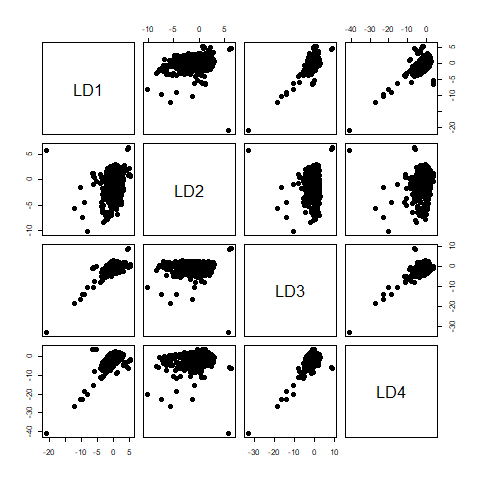

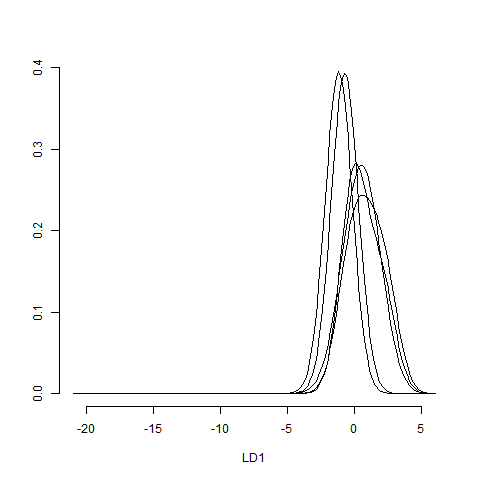

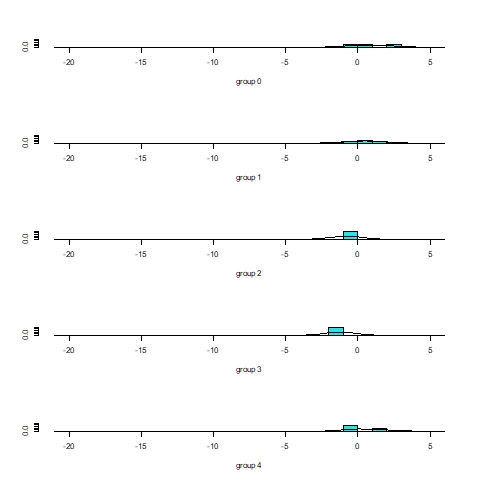

In [38]:
%%R
plot(res.lda,
     panel = function(x, y, ...) { points(x, y, cex = 2, ...) },
     col = as.integer(setEntrena$category), pch = 20)
plot(res.lda, dimen = 1, type ="density")
plot(res.lda, dimen = 1, type ="b")

Como podemos ver, LDA no es capaz de separar bien las clases, por lo que evaluamos si el dataset está desequilibrado

In [39]:
%%R
table(dfMedidas$category)
prop.table(table(dfMedidas$category)) * 100


          0           1           2           3           4           5 
 0.00758452 99.90329737  0.07963746  0.00189613  0.00568839  0.00189613 


Como podemos ver, la variable objetivo está extremadamente desequilibrada, por lo que para mantener un bajo coste computacional y energético, seguiremos con el dataset con menos instancias.